# Module 03: Neurons, Perceptrons, and Multilayer Perceptrons

This module builds deep learning from the smallest useful unit: one neuron. It then moves to perceptrons, linear separability, hidden layers, and full multilayer perceptrons (MLPs). The examples use small datasets first, then a curved two-moons dataset so the need for hidden layers becomes visible.


## Module outline

* **Step 1: Artificial Neuron Foundations**
  * Biological inspiration, artificial neuron, input feature, weight, bias, weighted sum, activation output, neuron score.
* **Step 2: Perceptron for Binary Decisions**
  * Perceptron, threshold, sign/step function, decision boundary, weight direction, bias shift, hard prediction.
* **Step 3: Perceptron Learning Rule**
  * Prediction error, update rule, learning rate, epoch, mistake-driven learning, convergence, limitation.
* **Step 4: Linear Separability**
  * Linearly separable data, non-linearly separable data, AND, OR, XOR, why one line is not enough.
* **Step 5: Hidden Layers**
  * Hidden neuron, hidden layer, nonlinear activation, learned feature, feature transformation, why activation is required.
* **Step 6: MLP Architecture**
  * Input layer, dense layer, hidden layer, output layer, width, depth, parameter count, forward pass, classification head, regression head.
* **Step 7: Capacity and Generalization**
  * Model capacity, underfitting, overfitting, validation gap, memorization, width vs depth, regularization preview.
* **Step 8: Universal Approximation Intuition**
  * Piecewise approximation, nonlinear functions, theorem meaning, theorem limitation, practical interpretation.
* **Step 9: Practical MLP Implementation**
  * XOR MLP, two-moons dataset, scaling, training, decision boundary, probability interpretation.
* **Step 10: Common MLP Mistakes**
  * Missing activation, wrong output layer, wrong loss, shape mismatch, unscaled features, reading logits as probabilities.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import make_moons, make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import accuracy_score, classification_report, mean_absolute_error, mean_squared_error

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['font.size'] = 10
rng = np.random.default_rng(42)


## Step 1: Artificial Neuron Foundations

An artificial neuron is a small calculator. It multiplies each input by a weight, adds the results, adds a bias, and usually applies an activation function.

$$z=w_1x_1+w_2x_2+\cdots+w_dx_d+b$$

$$a=f(z)$$

The weighted sum $z$ is the raw score. The activation output $a$ is the value passed to the next layer.


### 1.1 Artificial neuron

**Definition:** A computation unit that converts input numbers into one output number.

**Where it is used:** Every dense layer, convolution layer, and transformer feed-forward block is built from neuron-like weighted calculations.

**Why it matters:** It gives the network a trainable way to detect patterns.

**Simple example:** If a neuron sees study_hours and attendance, it can learn that both increase pass probability.

**Common mistake:** Thinking the neuron contains human-like reasoning. It is only arithmetic.


### 1.2 Input feature

**Definition:** One measured value given to the model.

**Where it is used:** Pixels, token embeddings, tabular columns, audio samples, and sensor readings.

**Why it matters:** The model cannot learn from information that is not represented as input features.

**Simple example:** For a student example, hours_studied is one feature and attendance_rate is another.

**Common mistake:** Mixing raw identifiers with meaningful numeric features without proper encoding.


### 1.3 Weight

**Definition:** A trainable number that controls how strongly one input affects the neuron score.

**Where it is used:** Weights are learned in every neural-network layer.

**Why it matters:** Positive weights push the score up; negative weights push it down; near-zero weights make the feature weak.

**Simple example:** If weight for hours_studied is 2.0, increasing hours has a strong positive effect.

**Common mistake:** Calling every positive weight good and every negative weight bad. Sign only tells direction.


### 1.4 Bias

**Definition:** A trainable constant added after the weighted inputs.

**Where it is used:** Every dense neuron usually has a bias term.

**Why it matters:** It moves the activation threshold so the neuron is not forced to switch at the origin.

**Simple example:** A pass/fail neuron may need some base difficulty even when features are zero.

**Common mistake:** Forgetting that bias has one value per neuron, not one value per input row.


### 1.5 Weighted sum

**Definition:** The raw linear score $x^Tw+b$ before activation.

**Where it is used:** It is the first calculation inside dense layers and output heads.

**Why it matters:** It combines many features into one score the next operation can use.

**Simple example:** $[2, 0.5]\cdot[1.5,-2]+0.25=2.25$.

**Common mistake:** Treating the weighted sum as a probability. It is a raw score.


### 1.6 Activation output

**Definition:** The result after applying an activation function to the weighted sum.

**Where it is used:** Hidden layers use activations like ReLU or GELU; output layers use task-specific activations.

**Why it matters:** It introduces nonlinearity and controls the range or meaning of a neuron output.

**Simple example:** Sigmoid turns score 2.25 into a value close to 0.90.

**Common mistake:** Using sigmoid everywhere just because it returns 0 to 1.


In [2]:
x = np.array([2.0, 0.5])
w = np.array([1.5, -2.0])
b = 0.25
z = x @ w + b
a = 1/(1+np.exp(-z))
print('weighted sum z:', z)
print('sigmoid activation output:', a)


weighted sum z: 2.25
sigmoid activation output: 0.9046505351008906


**Output meaning:** the first feature pushes the neuron upward and the second feature pushes it downward. The final positive score becomes a high sigmoid value.


## Step 2: Perceptron for Binary Decisions

A perceptron is a neuron used for a hard yes/no decision.

$$\hat{y}=1 \text{ if } x^Tw+b \ge 0, \text{ otherwise } 0$$

The boundary $x^Tw+b=0$ is a line in two dimensions, a plane in three dimensions, and a hyperplane in higher dimensions.


### 2.1 Threshold

**Definition:** The cutoff that converts a score into class 0 or class 1.

**Where it is used:** Classic perceptrons and some simple rule-based classifiers.

**Why it matters:** It changes continuous scores into decisions.

**Simple example:** If score is 0.7 and threshold is 0, predict 1.

**Common mistake:** Thinking thresholding is differentiable. Hard threshold has no useful gradient.


### 2.2 Decision boundary

**Definition:** The place where the model switches from one class to another.

**Where it is used:** Classification models, visualization, debugging decision regions.

**Why it matters:** It shows what rule the model has learned.

**Simple example:** For $x_1+x_2-0.5=0$, points above the line are class 1.

**Common mistake:** Thinking all boundaries must be straight. Only a single perceptron has a straight boundary.


### 2.3 Weight direction

**Definition:** The direction where the perceptron score increases fastest.

**Where it is used:** Interpreting linear classifiers and perceptrons.

**Why it matters:** It explains which side of the boundary becomes positive.

**Simple example:** Weights [1,1] point toward larger x1 and x2 values.

**Common mistake:** Reading weight direction without considering feature scaling.


### 2.4 Bias shift

**Definition:** Movement of the boundary without changing its angle.

**Where it is used:** Linear models and dense neurons.

**Why it matters:** It lets the boundary fit data away from zero.

**Simple example:** Changing bias from 0 to -1 shifts the line.

**Common mistake:** Removing bias and expecting the same flexibility.


In [3]:
X_gate = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)
y_or = np.array([0,1,1,1])
w = np.array([1.0, 1.0]); b = -0.5
score = X_gate @ w + b
pred = (score >= 0).astype(int)
display(pd.DataFrame({'x1':X_gate[:,0], 'x2':X_gate[:,1], 'score':score, 'prediction':pred, 'target_OR':y_or}))


,x1,x2,score,prediction,target_OR
0,0.0,0.0,-0.5,0,0
1,0.0,1.0,0.5,1,1
2,1.0,0.0,0.5,1,1
3,1.0,1.0,1.5,1,1


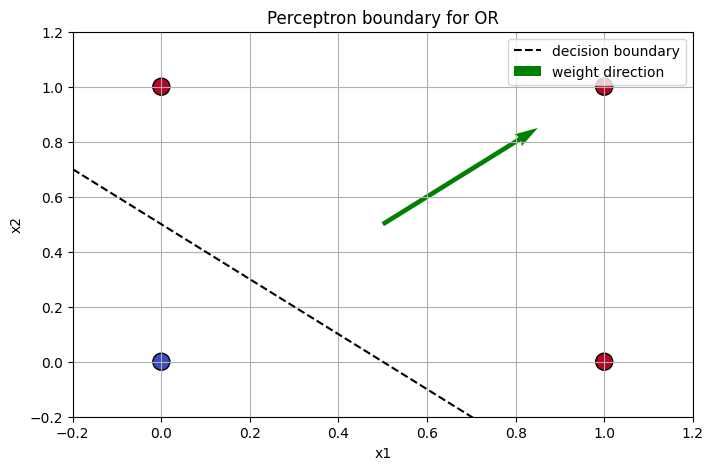

In [4]:
plt.scatter(X_gate[:,0], X_gate[:,1], c=y_or, cmap='coolwarm', s=150, edgecolor='k')
xline = np.linspace(-.2,1.2,100)
plt.plot(xline, -xline + .5, 'k--', label='decision boundary')
plt.quiver(.5,.5,.35,.35, angles='xy', scale_units='xy', scale=1, color='green', label='weight direction')
plt.xlim(-.2,1.2); plt.ylim(-.2,1.2)
plt.title('Perceptron boundary for OR')
plt.xlabel('x1'); plt.ylabel('x2'); plt.legend();


## Step 3: Perceptron Learning Rule

The perceptron learns only when it makes a mistake.

$$w_{new}=w_{old}+\eta(y-\hat{y})x$$
$$b_{new}=b_{old}+\eta(y-\hat{y})$$

If prediction is correct, $y-\hat{y}=0$, so there is no update. If prediction is wrong, the boundary moves toward a better position.


### 3.1 Prediction error

**Definition:** The difference between target and predicted class.

**Where it is used:** Perceptron updates and many loss functions.

**Why it matters:** It tells the learning rule what direction to correct.

**Simple example:** If target is 1 and prediction is 0, error is +1.

**Common mistake:** Using hard perceptron error for modern deep networks; modern nets use differentiable losses.


### 3.2 Learning rate

**Definition:** A small multiplier controlling update size.

**Where it is used:** Optimizers in all neural networks.

**Why it matters:** Too large can jump around; too small learns slowly.

**Simple example:** With learning rate 0.1, an error update is smaller than with 1.0.

**Common mistake:** Treating learning rate as a fixed perfect value for every problem.


### 3.3 Epoch

**Definition:** One full pass through the training data.

**Where it is used:** Training loops for ML and DL models.

**Why it matters:** One pass is usually not enough for learning.

**Simple example:** If 1000 samples are processed once, that is one epoch.

**Common mistake:** Confusing epoch with one gradient update.


### 3.4 Convergence

**Definition:** The point where updates stop changing the solution much.

**Where it is used:** Training monitoring and stopping criteria.

**Why it matters:** It tells whether the model has found a stable rule.

**Simple example:** A linearly separable OR perceptron can reach zero mistakes.

**Common mistake:** Expecting convergence on non-linearly separable data with one perceptron.


In [5]:
X = X_gate; y = y_or
w = np.zeros(2); b = 0.0; eta = 0.2
history = []
for epoch in range(8):
    mistakes = 0
    for xi, yi in zip(X, y):
        pred = int(xi @ w + b >= 0)
        err = yi - pred
        if err:
            w += eta * err * xi
            b += eta * err
            mistakes += 1
    history.append({'epoch':epoch+1,'w1':w[0],'w2':w[1],'bias':b,'mistakes':mistakes})
display(pd.DataFrame(history))


,epoch,w1,w2,bias,mistakes
0,1,0.0,0.2,0.0,2
1,2,0.2,0.2,0.0,2
2,3,0.2,0.2,-0.2,1
3,4,0.2,0.2,-0.2,0
4,5,0.2,0.2,-0.2,0
5,6,0.2,0.2,-0.2,0
6,7,0.2,0.2,-0.2,0
7,8,0.2,0.2,-0.2,0


## Step 4: Linear Separability

Linear separability means a single straight boundary can split the classes. AND and OR are linearly separable. XOR is not because the positive points are diagonal from each other.


### 4.1 Linearly separable data

**Definition:** Data whose classes can be split by one straight boundary.

**Where it is used:** Perceptrons, linear classifiers, SVM intuition.

**Why it matters:** It tells whether a simple linear model can solve the task.

**Simple example:** OR data is separable by the line $x_1+x_2=0.5$.

**Common mistake:** Judging separability only from one plot when data has many dimensions.


### 4.2 Non-linearly separable data

**Definition:** Data that needs a curved or multi-part boundary.

**Where it is used:** MLPs, kernels, trees, and nonlinear models.

**Why it matters:** It explains why hidden layers are needed.

**Simple example:** XOR cannot be split by one straight line.

**Common mistake:** Trying to fix XOR only by training a single perceptron longer.


### 4.3 XOR problem

**Definition:** A two-input problem where output is 1 only when inputs differ.

**Where it is used:** Teaching hidden layers and nonlinearity.

**Why it matters:** It is the smallest example showing a single perceptron limitation.

**Simple example:** [0,1] and [1,0] are class 1; [0,0] and [1,1] are class 0.

**Common mistake:** Thinking XOR is important as a dataset; it is important as a concept.


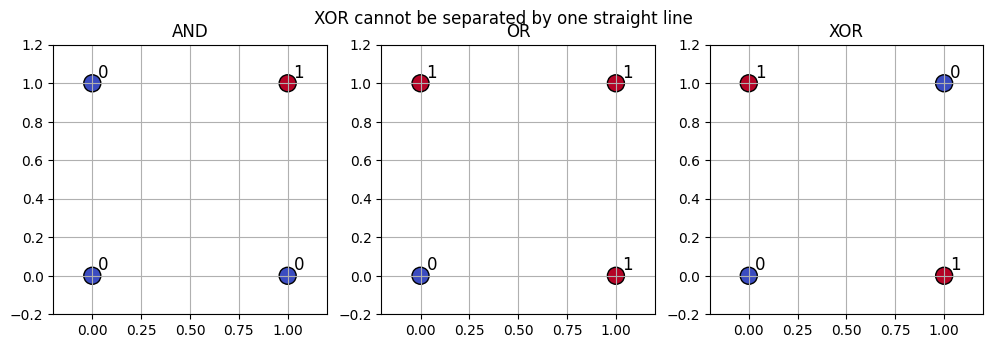

In [6]:
gates = {'AND':[0,0,0,1], 'OR':[0,1,1,1], 'XOR':[0,1,1,0]}
fig, axes = plt.subplots(1,3,figsize=(12,3.5))
for ax,(name,labels) in zip(axes,gates.items()):
    labels=np.array(labels)
    ax.scatter(X_gate[:,0], X_gate[:,1], c=labels, cmap='coolwarm', s=150, edgecolor='k')
    for xpt, lab in zip(X_gate, labels):
        ax.text(xpt[0]+.03,xpt[1]+.03,str(lab),fontsize=12)
    ax.set_title(name); ax.set_xlim(-.2,1.2); ax.set_ylim(-.2,1.2)
plt.suptitle('XOR cannot be separated by one straight line');


## Step 5: Hidden Layers

A hidden layer creates new features from the original input. Each hidden neuron can detect a simple pattern; the next layer combines those patterns into a more useful decision.

The key point is nonlinearity. Without activation functions, many linear layers collapse into one linear layer.


### 5.1 Hidden neuron

**Definition:** A neuron whose output is not the final prediction.

**Where it is used:** Middle layers of neural networks.

**Why it matters:** It can detect an intermediate pattern useful for later layers.

**Simple example:** One neuron might detect high x1, another might detect low x2.

**Common mistake:** Expecting each hidden neuron to have a clean human label.


### 5.2 Hidden layer

**Definition:** A group of hidden neurons at the same depth.

**Where it is used:** MLPs, CNN classifier heads, transformer feed-forward blocks.

**Why it matters:** It creates a learned representation from raw input.

**Simple example:** A 16-unit hidden layer creates 16 new features.

**Common mistake:** Thinking more hidden units always improves validation performance.


### 5.3 Nonlinear activation

**Definition:** A function like ReLU, sigmoid, tanh, or GELU applied after $XW+b$.

**Where it is used:** Almost every hidden layer in deep learning.

**Why it matters:** It prevents stacked layers from becoming just one linear transformation.

**Simple example:** ReLU turns negative scores to 0 and keeps positive scores.

**Common mistake:** Leaving out activation and wondering why deep model acts linear.


### 5.4 Learned feature

**Definition:** An internal representation created by the model instead of manually designed.

**Where it is used:** Hidden layers and embeddings.

**Why it matters:** It lets the model discover useful combinations.

**Simple example:** In XOR, hidden features can represent parts of the input space.

**Common mistake:** Assuming learned features are always easy to interpret.


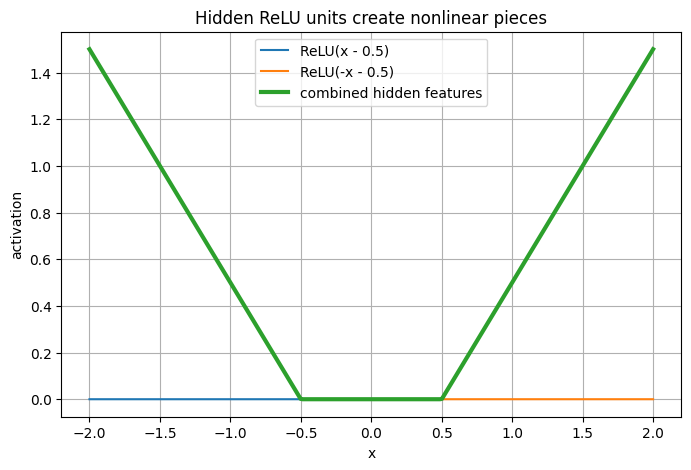

In [7]:
xx = np.linspace(-2,2,300)
h1 = np.maximum(0, xx-.5)
h2 = np.maximum(0, -xx-.5)
plt.plot(xx,h1,label='ReLU(x - 0.5)')
plt.plot(xx,h2,label='ReLU(-x - 0.5)')
plt.plot(xx,h1+h2,label='combined hidden features',linewidth=3)
plt.title('Hidden ReLU units create nonlinear pieces')
plt.xlabel('x'); plt.ylabel('activation'); plt.legend();


## Step 6: MLP Architecture

An MLP is a stack of dense layers. A common forward pass is:

$$H=f(XW_1+b_1)$$
$$\hat{Y}=g(HW_2+b_2)$$

The hidden layer learns features. The output layer converts those features into task-specific predictions.


### 6.1 Input layer

**Definition:** The shape of the data entering the model.

**Where it is used:** Every network architecture.

**Why it matters:** It determines how many input weights the first layer needs.

**Simple example:** A table with 20 features needs input width 20.

**Common mistake:** Calling input layer a trainable layer when it often only represents input shape.


### 6.2 Dense layer

**Definition:** A layer where every input connects to every output unit.

**Where it is used:** MLPs and classifier heads after CNN/transformer features.

**Why it matters:** It mixes all input features together.

**Simple example:** Input width 3 and output width 5 needs weights shape (3,5).

**Common mistake:** Using dense layers on huge images directly without considering parameter explosion.


### 6.3 Width

**Definition:** Number of units in a layer.

**Where it is used:** Architecture design.

**Why it matters:** More width can represent more features but adds parameters.

**Simple example:** A hidden layer with 64 neurons is wider than one with 16.

**Common mistake:** Increasing width without validation.


### 6.4 Depth

**Definition:** Number of transformation layers.

**Where it is used:** Architecture design and representation learning.

**Why it matters:** More depth can build hierarchical features.

**Simple example:** A network with three hidden layers is deeper than one hidden layer.

**Common mistake:** Adding depth without activation, normalization, or enough data.


### 6.5 Parameter count

**Definition:** Number of trainable weights and biases.

**Where it is used:** Model sizing and overfitting checks.

**Why it matters:** It estimates memory, compute, and capacity.

**Simple example:** A dense layer from 10 to 4 has 10*4+4=44 parameters.

**Common mistake:** Ignoring bias terms when counting parameters.


In [8]:
batch, features, hidden, outputs = 5, 3, 4, 2
X_demo = rng.normal(size=(batch, features))
W1 = rng.normal(size=(features, hidden)); b1 = np.zeros(hidden)
W2 = rng.normal(size=(hidden, outputs)); b2 = np.zeros(outputs)
H = np.maximum(0, X_demo @ W1 + b1)
logits = H @ W2 + b2
print('X', X_demo.shape, 'H', H.shape, 'logits', logits.shape)
print('parameter count:', W1.size+b1.size+W2.size+b2.size)


X (5, 3) H (5, 4) logits (5, 2)
parameter count: 26


## Step 7: Capacity and Generalization

Capacity is how many patterns a model can represent. Too little capacity causes underfitting. Too much capacity can cause overfitting if the model memorizes training details.


### 7.1 Underfitting

**Definition:** Model is too simple or poorly trained to capture the pattern.

**Where it is used:** Training diagnostics.

**Why it matters:** Both train and validation errors stay high.

**Simple example:** A linear model on two-moons data underfits.

**Common mistake:** Trying regularization when the real issue is not enough capacity.


### 7.2 Overfitting

**Definition:** Model fits training data too closely and performs worse on unseen data.

**Where it is used:** Validation monitoring.

**Why it matters:** It means the learned rule may not generalize.

**Simple example:** Training loss falls while validation loss rises.

**Common mistake:** Judging model only by training accuracy.


### 7.3 Validation gap

**Definition:** Difference between train performance and validation performance.

**Where it is used:** Model selection and early stopping.

**Why it matters:** A large gap often signals overfitting.

**Simple example:** Train accuracy 99%, validation accuracy 75%.

**Common mistake:** Assuming every gap is bad; some gap is normal.


### 7.4 Regularization preview

**Definition:** Methods that reduce overfitting.

**Where it is used:** Dropout, weight decay, data augmentation, early stopping.

**Why it matters:** They limit memorization and improve generalization.

**Simple example:** Weight decay discourages very large weights.

**Common mistake:** Using heavy regularization before fixing data leakage or bad splits.


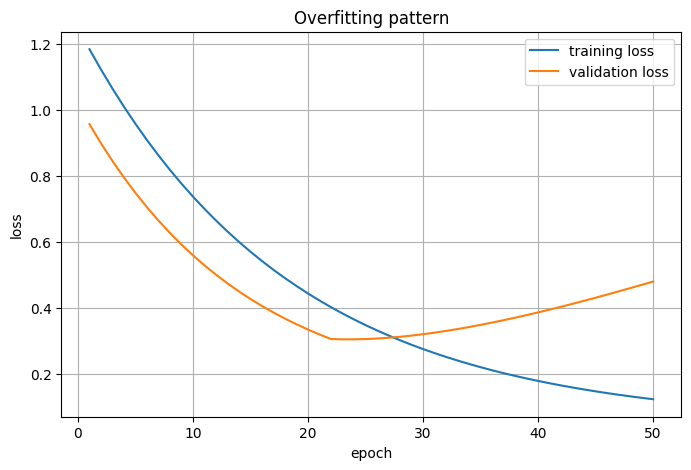

In [9]:
epochs=np.arange(1,51)
train=1.2*np.exp(-epochs/18)+.05
val=0.9*np.exp(-epochs/14)+.12+.012*np.maximum(epochs-22,0)
plt.plot(epochs,train,label='training loss')
plt.plot(epochs,val,label='validation loss')
plt.title('Overfitting pattern'); plt.xlabel('epoch'); plt.ylabel('loss'); plt.legend();


## Step 8: Universal Approximation Intuition

The universal approximation theorem says a network with enough hidden units can approximate many continuous functions. Practically, hidden units combine many simple nonlinear pieces into a complex shape. It does not guarantee easy training, small data needs, or good generalization.


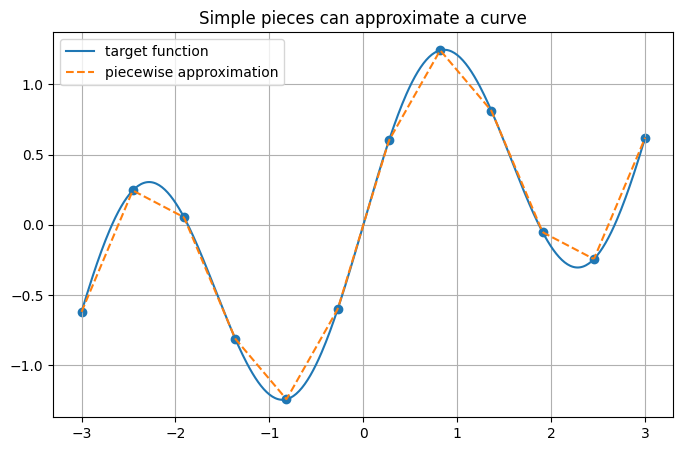

In [10]:
x=np.linspace(-3,3,400)
y=np.sin(2*x)+0.3*x
knots=np.linspace(-3,3,12)
piece=np.interp(x,knots,np.sin(2*knots)+0.3*knots)
plt.plot(x,y,label='target function')
plt.plot(x,piece,'--',label='piecewise approximation')
plt.scatter(knots,np.sin(2*knots)+0.3*knots)
plt.title('Simple pieces can approximate a curve'); plt.legend();


## Step 9: Practical MLP Implementation

This section uses two examples: a from-scratch XOR MLP and a scikit-learn MLP on the two-moons dataset.


,x1,x2,target,probability,class
0,0.0,0.0,0.0,0.031340,0
1,0.0,1.0,1.0,0.971255,1
2,1.0,0.0,1.0,0.969339,1
3,1.0,1.0,0.0,0.032167,0


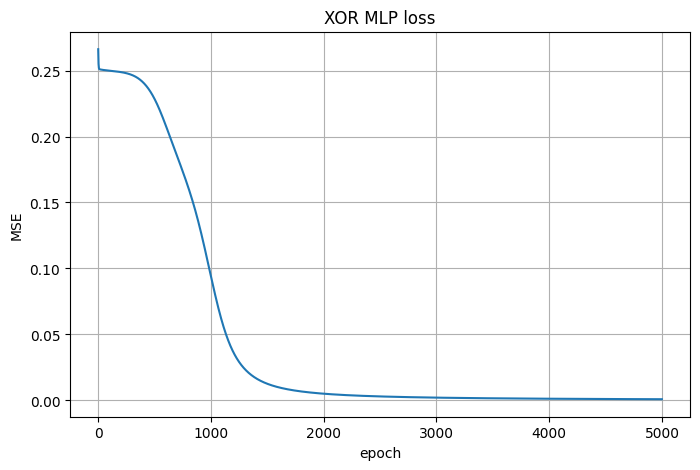

In [11]:
X = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)
y = np.array([[0],[1],[1],[0]], dtype=float)
def sig(z): return 1/(1+np.exp(-z))
def sigg(a): return a*(1-a)
W1=rng.normal(scale=.8,size=(2,4)); b1=np.zeros((1,4))
W2=rng.normal(scale=.8,size=(4,1)); b2=np.zeros((1,1))
losses=[]
for epoch in range(5000):
    H=sig(X@W1+b1); yh=sig(H@W2+b2)
    losses.append(np.mean((yh-y)**2))
    dz2=2*(yh-y)/len(X)*sigg(yh)
    dW2=H.T@dz2; db2=dz2.sum(axis=0,keepdims=True)
    dz1=(dz2@W2.T)*sigg(H)
    dW1=X.T@dz1; db1=dz1.sum(axis=0,keepdims=True)
    W1-=.8*dW1; b1-=.8*db1; W2-=.8*dW2; b2-=.8*db2
display(pd.DataFrame({'x1':X[:,0],'x2':X[:,1],'target':y.ravel(),'probability':yh.ravel(),'class':(yh.ravel()>.5).astype(int)}))
plt.plot(losses); plt.title('XOR MLP loss'); plt.xlabel('epoch'); plt.ylabel('MSE');


test accuracy: 0.97
              precision    recall  f1-score   support

           0       0.95      0.99      0.97       150
           1       0.99      0.95      0.97       150

    accuracy                           0.97       300
   macro avg       0.97      0.97      0.97       300
weighted avg       0.97      0.97      0.97       300



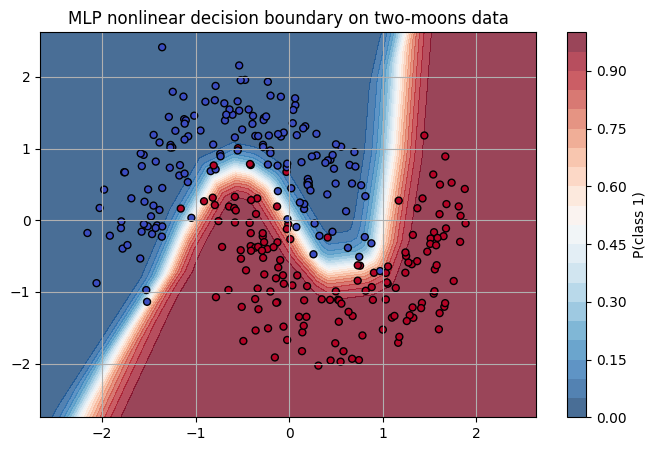

In [12]:
Xm, ym = make_moons(n_samples=1200, noise=.22, random_state=42)
Xtr, Xte, ytr, yte = train_test_split(Xm, ym, test_size=.25, random_state=42, stratify=ym)
sc = StandardScaler()
Xtr = sc.fit_transform(Xtr); Xte = sc.transform(Xte)
clf = MLPClassifier(hidden_layer_sizes=(16,16), activation='relu', max_iter=1000, random_state=42)
clf.fit(Xtr,ytr)
pred=clf.predict(Xte)
print('test accuracy:', round(accuracy_score(yte,pred),3))
print(classification_report(yte,pred))
xx,yy=np.meshgrid(np.linspace(Xtr[:,0].min()-.5,Xtr[:,0].max()+.5,250),np.linspace(Xtr[:,1].min()-.5,Xtr[:,1].max()+.5,250))
grid=np.c_[xx.ravel(),yy.ravel()]
prob=clf.predict_proba(grid)[:,1].reshape(xx.shape)
plt.contourf(xx,yy,prob,levels=20,cmap='RdBu_r',alpha=.75)
plt.colorbar(label='P(class 1)')
plt.scatter(Xte[:,0],Xte[:,1],c=yte,cmap='coolwarm',edgecolor='k',s=25)
plt.title('MLP nonlinear decision boundary on two-moons data');


## Deep Dive A: What a Neuron Really Learns

A neuron does not memorize a sentence like “this is class 1.” It learns a **direction in feature space**.

For two input features, the neuron score is:

$$z=w_1x_1+w_2x_2+b$$

The values of $w_1$ and $w_2$ decide the direction where the score increases. The bias decides where the switching point is placed. This is why feature scaling matters: if one feature has values around 10,000 and another feature has values around 0.1, the large-scale feature can dominate the score before training even becomes stable.

In a real MLP, hidden neurons learn many such directions. The next layer combines those directions into a more complex rule.


In [13]:
# Same logical rule, different feature scale
small_scale = np.array([[1.0, 1.0], [2.0, 1.0], [1.0, 2.0]])
large_scale = small_scale.copy()
large_scale[:, 0] *= 1000
w = np.array([1.0, 1.0])
b = 0.0
print('scores with similar scales:', small_scale @ w + b)
print('scores when feature 1 is 1000x larger:', large_scale @ w + b)


scores with similar scales: [2. 3. 3.]
scores when feature 1 is 1000x larger: [1001. 2001. 1002.]


**What this shows:** the same weight vector behaves very differently when the feature scales are different. That is why MLP examples should usually standardize numeric features before training.


## Deep Dive B: Single Perceptron vs MLP Boundary

A single perceptron can create only one straight boundary. An MLP can create a boundary made from many small pieces because each hidden neuron creates a different intermediate feature.

This difference is not just theory. It changes what the model can learn:

* If the class rule is almost straight, a simple perceptron or logistic regression may be enough.
* If the class rule bends, crosses, or depends on feature interactions, hidden layers become useful.
* If the data is small and noisy, a large MLP may still overfit even though it is more powerful.


linear model accuracy: 0.837
MLP accuracy: 0.94


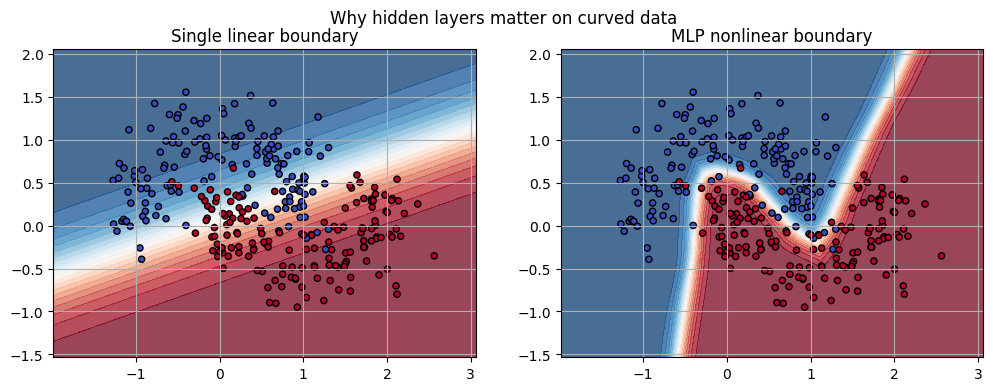

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

Xm, ym = make_moons(n_samples=1000, noise=0.25, random_state=7)
X_train, X_test, y_train, y_test = train_test_split(Xm, ym, test_size=0.3, random_state=7, stratify=ym)

linear_model = make_pipeline(StandardScaler(), LogisticRegression())
mlp_model = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(32, 32), max_iter=1200, random_state=7))
linear_model.fit(X_train, y_train)
mlp_model.fit(X_train, y_train)

print('linear model accuracy:', round(linear_model.score(X_test, y_test), 3))
print('MLP accuracy:', round(mlp_model.score(X_test, y_test), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, model, title in zip(axes, [linear_model, mlp_model], ['Single linear boundary', 'MLP nonlinear boundary']):
    xx, yy = np.meshgrid(np.linspace(Xm[:,0].min()-0.5, Xm[:,0].max()+0.5, 250),
                         np.linspace(Xm[:,1].min()-0.5, Xm[:,1].max()+0.5, 250))
    grid = np.c_[xx.ravel(), yy.ravel()]
    prob = model.predict_proba(grid)[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, prob, levels=20, cmap='RdBu_r', alpha=0.75)
    ax.scatter(X_test[:,0], X_test[:,1], c=y_test, cmap='coolwarm', s=20, edgecolor='k')
    ax.set_title(title)
plt.suptitle('Why hidden layers matter on curved data');


**Output meaning:** the linear model must cut the space with one broad line. The MLP can bend the decision region around the two moon shapes.


## Deep Dive C: XOR Hidden-Layer Logic in Plain Words

XOR feels confusing because the output is not based on “more of x1” or “more of x2.” It depends on a relationship:

* `[0, 0]` → same values → class 0
* `[1, 1]` → same values → class 0
* `[0, 1]` → different values → class 1
* `[1, 0]` → different values → class 1

A hidden layer can solve this by creating intermediate checks, such as:

* one hidden neuron detects “at least one input is active”
* another hidden neuron detects “both inputs are active”
* the output combines them as “at least one active, but not both”

This is the important idea: hidden layers turn the original problem into a new feature space where the final output layer can separate the classes.


In [15]:
xor_table = pd.DataFrame({
    'x1': [0,0,1,1],
    'x2': [0,1,0,1],
})
xor_table['at_least_one_active'] = ((xor_table.x1 + xor_table.x2) >= 1).astype(int)
xor_table['both_active'] = ((xor_table.x1 + xor_table.x2) == 2).astype(int)
xor_table['xor_from_hidden_logic'] = ((xor_table.at_least_one_active == 1) & (xor_table.both_active == 0)).astype(int)
display(xor_table)


,x1,x2,at_least_one_active,both_active,xor_from_hidden_logic
0,0,0,0,0,0
1,0,1,1,0,1
2,1,0,1,0,1
3,1,1,1,1,0


**Output meaning:** the hidden features make XOR understandable. The final rule no longer needs to separate diagonal points directly; it uses the two intermediate checks.


## Deep Dive D: Choosing MLP Size

There is no single correct number of hidden layers or neurons. The choice depends on data size, noise, feature complexity, and validation performance.

| Symptom | Likely issue | Better next action |
|---|---|---|
| Train and validation accuracy both low | underfitting | increase useful features, model size, epochs, or improve optimization |
| Train accuracy high, validation accuracy low | overfitting | use more data, regularization, early stopping, smaller model |
| Training loss does not move | optimization issue | check scaling, learning rate, activation, initialization |
| Accuracy unstable between runs | high variance | use validation split, repeated runs, simpler model, more data |

The correct model is not the biggest model. The correct model is the one that learns the pattern and generalizes.


## Missing Concept Expansion: More Neuron, Perceptron, and MLP Concepts

This section fills the concepts that are easy to skip but important for a complete MLP foundation.


### McCulloch-Pitts Neuron vs Modern Artificial Neuron

The early McCulloch-Pitts neuron used binary inputs and a hard threshold. It was useful historically because it showed that logic-like decisions could be built from simple units.

A modern artificial neuron is more flexible:

* inputs can be continuous numbers, not only 0/1;
* weights and biases are learned from data;
* hidden layers usually use differentiable activations;
* outputs are trained with gradient-based optimization.

**Why this matters:** the perceptron is a bridge between logic rules and modern trainable neural networks.


### Hard Threshold vs Differentiable Activation

A hard threshold produces an exact 0 or 1 decision. That is easy to understand but difficult for gradient descent because the derivative is zero almost everywhere.

Modern neural networks usually use differentiable or piecewise differentiable activations such as ReLU, sigmoid, tanh, or GELU. These activations give useful gradients for learning.

**Simple idea:** a perceptron makes a hard decision immediately; a modern neuron usually keeps a smooth training signal until the final prediction is needed.


### Hyperplane

In two features, a perceptron boundary is a line. In three features, it is a plane. In more than three features, it is called a hyperplane.

$$w^Tx+b=0$$

**Where it is used:** perceptrons, logistic regression, linear SVMs, and the final linear layers of neural networks.

**Common mistake:** thinking high-dimensional boundaries cannot be linear. They can be linear in high-dimensional feature space, even if we cannot draw them directly.


### Margin Intuition

Margin means how far a point is from the decision boundary. A point far from the boundary is classified with more confidence by a linear model. A point near the boundary is easier to flip.

Perceptrons do not explicitly maximize margin, but margin intuition helps explain why some boundaries generalize better than others.


,x1,x2,score,distance_to_boundary
0,0.2,0.2,0.0,0.000000
1,0.8,0.9,-0.1,0.070711
2,0.9,0.1,0.8,0.565685
3,0.1,0.8,-0.7,0.494975


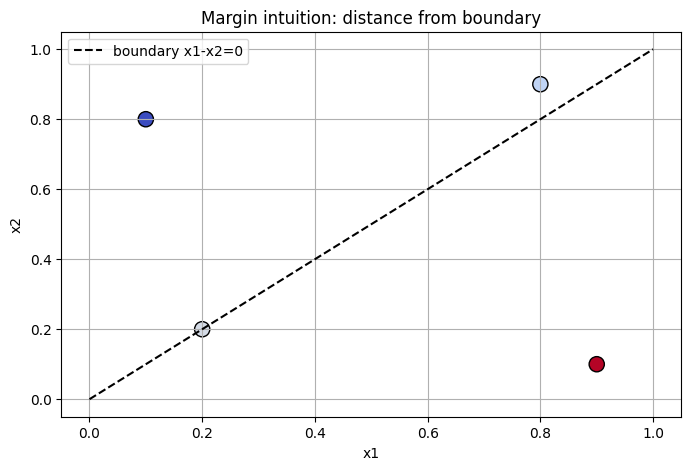

In [16]:
points = np.array([[0.2,0.2],[0.8,0.9],[0.9,0.1],[0.1,0.8]])
w = np.array([1.0, -1.0]); b = 0.0
scores = points @ w + b
distances = np.abs(scores) / np.linalg.norm(w)
display(pd.DataFrame({'x1':points[:,0], 'x2':points[:,1], 'score':scores, 'distance_to_boundary':distances}))
plt.scatter(points[:,0], points[:,1], c=scores, cmap='coolwarm', s=120, edgecolor='k')
xline=np.linspace(0,1,100)
plt.plot(xline, xline, 'k--', label='boundary x1-x2=0')
plt.title('Margin intuition: distance from boundary')
plt.xlabel('x1'); plt.ylabel('x2'); plt.legend();


### Perceptron Convergence Theorem Intuition

If data is linearly separable, the perceptron learning rule can eventually find a separating boundary. If data is not linearly separable, it may keep making updates forever.

This is not a promise that the perceptron finds the best boundary. It only says a separating boundary can be found under the right conditions.

**Where it is used:** to understand why XOR cannot be fixed by simply training a single perceptron longer.


### Multiclass Perceptron and One-vs-Rest

A basic perceptron is binary. For multiple classes, one simple strategy is one-vs-rest:

* train one classifier for each class;
* each classifier asks “is this my class or not?”;
* choose the class with the highest score.

Modern neural networks usually use one output logit per class and softmax, but the idea of class-specific scores is similar.


### MLP as Feature Learner + Linear Head

An MLP can be understood as two parts:

1. hidden layers learn a new representation of the input;
2. the final layer applies a simple output rule to that representation.

This is why hidden layers are powerful. They transform the data so that the final layer has an easier job.


In [17]:
Xm, ym = make_moons(n_samples=500, noise=.18, random_state=11)
sc = StandardScaler()
Xs = sc.fit_transform(Xm)
clf = MLPClassifier(hidden_layer_sizes=(8,), activation='relu', max_iter=1200, random_state=11)
clf.fit(Xs, ym)
hidden = np.maximum(0, Xs @ clf.coefs_[0] + clf.intercepts_[0])
print('original feature shape:', Xs.shape)
print('learned hidden representation shape:', hidden.shape)
display(pd.DataFrame(hidden[:5], columns=[f'hidden_{i}' for i in range(hidden.shape[1])]))


original feature shape: (500, 2)
learned hidden representation shape: (500, 8)


,hidden_0,hidden_1,hidden_2,hidden_3,hidden_4,hidden_5,hidden_6,hidden_7
0,0.000000,0.538750,0.0,0.000000,0.000000,0.000000,1.352572,0.0
1,0.333995,0.689062,0.0,0.000000,0.492159,0.370368,0.890403,0.0
2,0.839207,0.098541,0.0,0.000000,1.853635,2.256380,0.000000,0.0
3,1.831515,1.368029,0.0,0.000000,2.196420,2.418224,0.000000,0.0
4,0.000000,0.000000,0.0,2.631102,0.000000,0.000000,0.000000,0.0


### Dense Layer Parameter Explosion

A dense layer connects every input to every output. That is flexible, but it can create many parameters.

$$parameters = input\_features \times output\_units + output\_units$$

This is why raw high-resolution images are usually processed by convolutional layers before dense layers.


In [18]:
examples = pd.DataFrame({
    'input_features':[20, 784, 224*224*3],
    'output_units':[64, 128, 1000],
})
examples['parameters'] = examples.input_features * examples.output_units + examples.output_units
display(examples)


,input_features,output_units,parameters
0,20,64,1344
1,784,128,100480
2,150528,1000,150529000


### Early Stopping for MLPs

Early stopping means stopping training when validation performance stops improving. It is a practical regularization method.

**Why it helps:** an MLP may first learn general patterns, then later start memorizing training noise. Early stopping keeps the model closer to the useful stage.

**Common mistake:** using test data for early stopping. Validation data should guide stopping; test data should be saved for final evaluation.


### MLP Hyperparameters Preview

Important MLP hyperparameters include:

| Hyperparameter | Meaning | Effect |
|---|---|---|
| hidden_layer_sizes | number and width of hidden layers | controls capacity |
| activation | hidden-layer nonlinearity | controls representation and gradients |
| learning_rate / learning_rate_init | update size | controls optimization speed/stability |
| alpha / weight_decay | penalty on large weights | helps reduce overfitting |
| batch_size | examples per update | affects gradient noise and speed |
| max_iter / epochs | training duration | too low underfits, too high may overfit |

These belong after understanding the architecture because each hyperparameter changes how the MLP learns.


## Step 10: Common MLP Mistakes

* **Missing hidden activation:** stacked linear layers are still linear.
* **Wrong output layer:** sigmoid, softmax, and linear outputs mean different things.
* **Wrong loss:** classification and regression need different losses.
* **Unscaled features:** MLPs usually train better when features are scaled.
* **Too much capacity:** large networks can memorize small datasets.
* **Reading logits as probabilities:** logits are raw scores, not probabilities.

## Module 03 Summary

A neuron calculates a weighted score. A perceptron makes a hard binary decision from that score. One perceptron solves only linearly separable problems. Hidden layers with nonlinear activations create learned features, allowing MLPs to solve curved and non-linear problems.
